# 01 · Vectorial, palabra clave e híbrido: ¿cuál recupera mejor?

**Pregunta del notebook:** si mides con un set de preguntas con respuesta conocida, ¿quién gana: la búsqueda
vectorial (denso), la de palabra clave (BM25) o la mezcla de ambas (híbrido)?

Qué vas a hacer (unos 12 minutos, sin API keys ni GPU):
1. Indexar 42 documentos de una empresa ficticia con **dos índices**: embeddings y BM25.
2. Medir 33 preguntas de tres tipos: **semánticas** (paráfrasis), **exactas** (un código) y **mixtas**.
3. Comprobar que fusionar «a ciegas» no garantiza nada, y **calibrar el híbrido con un set de ajuste separado del de prueba**.

## Glosario · buscar

Lo que necesitas para leer este notebook (puedes volver aquí cuando una palabra no te suene):

- **Embedding:** lista de números que representa el *significado* de un texto; textos con sentido parecido quedan «cerca», aunque no compartan palabras.
- **Similitud coseno:** qué tan cerca están dos embeddings (cerca de 1 = parecidos; cerca de 0 = nada que ver).
- **BM25:** puntaje por *palabras exactas*: cuenta qué documentos contienen las palabras de la pregunta y valora más las raras (`ERR-5012`) que las comunes. No entiende sinónimos; si no comparte ninguna palabra, no devuelve nada. Su puntaje no tiene tope y no es comparable con el coseno.
- **Top-k:** los *k* primeros resultados del ranking (top-3 = los tres mejores).
- **Índice:** estructura que se arma una vez para encontrar rápido (como el índice de un libro). Aquí hay dos: uno de embeddings y otro de BM25.
- **Trocear (*chunking*):** partir un documento en trozos antes de indexarlo.

## Glosario · medir y mezclar

Lo que necesitas para leer este notebook (puedes volver aquí cuando una palabra no te suene):

- **hit@3:** por pregunta, 1 si algún documento correcto está entre los 3 primeros y 0 si no. Se **promedia** sobre las preguntas.
- **MRR** (*Mean Reciprocal Rank*): por pregunta, 1 ÷ posición del primer documento correcto (1, ½, ⅓…; 0 si no aparece). Se **promedia** sobre las preguntas.
  *Ejemplo:* tres preguntas con el correcto en el puesto 1, en el 3 y sin aparecer → hit@3 = (1+1+0)/3 = 0.67; MRR = (1+0.33+0)/3 = 0.44.
- **Golden set:** tus preguntas con el documento correcto ya anotado: el «examen» del buscador.
- **Ajuste y prueba** (`dev` y `test` en el código): el peso α se elige con las preguntas de *ajuste* (17) y se informa con las de *prueba* (16), que no se tocan. Si no, evalúas con las respuestas a la vista.

- **RRF** (*Reciprocal Rank Fusion*, «fusión por rango recíproco»; rango = posición, recíproco = 1 ÷ algo; aquí «fusión simple 1:1»): mezcla **posiciones**, no puntajes: suma `1 / (60 + posición)` por cada lista donde aparece el documento (Σ = suma sobre las listas; 60 = constante que suaviza la diferencia entre puestos). No tiene α. No es un *reranker* (segundo modelo que reordena), ni MMR (diversificar resultados), ni MRR (métrica). *Ejemplo:* 2.º en una lista y 5.º en otra → 1/62 + 1/65 = 0.032.
- **Híbrido calibrado (convexo, con α):** mezcla **puntajes**: `α · minmax(coseno) + (1 − α) · minmax(BM25)`, donde `minmax(x) = (x − mín) / (máx − mín)` por pregunta lleva cada puntaje a 0–1. α = 1: solo significado; α = 0: solo palabras.
  *Ejemplo:* «¿Puedo trabajar desde mi casa?» con α = 0.7: Teletrabajo = 0.7·1.0 + 0.3·0 = 0.70; Devoluciones = 0.7·0.30 + 0.3·1.0 = 0.51.
- **Calibrar** es elegir α (solo existe en la mezcla de puntajes; el RRF no se calibra).

## Los datos de este notebook (qué es cada campo)

| Conjunto | Qué es | Campos de cada elemento |
|---|---|---|
| `DOCS` | 42 documentos cortos de la empresa ficticia (lo que se indexa y se busca) | `(id, título, texto, tipo)`. **id**: código único; la letra indica la familia (P política, T técnico, D distractor con código casi idéntico, E entidades). **título**: nombre corto. **texto**: contenido. **tipo**: categoría temática (no se usa para buscar). |
| `QUERIES` | 33 preguntas con respuesta conocida: el *golden set* | `(pregunta, tipo, relevantes)`. **tipo**: semántica, exacta o mixta. **relevantes**: id de los documentos correctos (el «juez»). |

Ejemplo: `("P01", "Vacaciones", "Los colaboradores acumulan 30 días…", "politica")` es un documento; `("¿Puedo trabajar desde mi casa?", "semantica", {"P02"})` es una pregunta cuyo documento correcto es *Teletrabajo*.

In [1]:
import importlib.util, subprocess, sys

for paquete, modulo in [("rank-bm25", "rank_bm25"), ("sentence-transformers", "sentence_transformers")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", paquete])
print("Entorno listo")

Entorno listo


In [2]:
#@title Datos sintéticos de «Andina Retail» (no necesitas leer esta celda) { display-mode: "form" }
"""Corpus sintético de «Andina Retail» para los notebooks del taller.

Se inserta tal cual en cada notebook (celda oculta con #@title), así cada uno corre solo en Colab.
Todo es inventado: las métricas que salgan ilustran un criterio, no miden producción.
"""

# ---------------------------------------------------------------- documentos
# ESQUEMA · DOCS (el corpus: 42 «documentos» cortos, cada uno es una tupla de 4 campos)
#   (id, título, texto, tipo)
#   id     código único del documento. La letra dice de qué familia es:
#            P = política interna · T = técnico (código exacto) · D = «distractor» (código casi idéntico a uno T)
#            E = entidades y relaciones (personas, equipos, sistemas; sirven para el notebook de grafo)
#   título nombre corto del documento (se indexa junto con el texto).
#   texto  contenido que se busca y que se le entregaría al modelo (1–3 frases).
#   tipo   categoría temática: politica · tecnico · producto · contrato · organizacion · incidente.
#          No se usa para buscar; solo describe el documento.
# Ejemplo: ("P01", "Vacaciones", "Los colaboradores acumulan 30 días…", "politica")
DOCS = [
    # Políticas (preguntas semánticas, con paráfrasis)
    ("P01", "Vacaciones", "Los colaboradores acumulan 30 días calendario de descanso remunerado por año de servicio. El periodo puede fraccionarse en bloques de mínimo 7 días con aprobación del jefe directo.", "politica"),
    ("P02", "Teletrabajo", "Se permite el trabajo remoto hasta tres días por semana. El día presencial obligatorio es el martes. Se requiere conexión VPN corporativa y equipo entregado por la empresa.", "politica"),
    ("P03", "Devoluciones", "El cliente puede devolver un producto dentro de 30 días desde la compra, con boleta y empaque sellado. Los productos de electrónica tienen un plazo de 15 días. El reembolso se realiza al mismo medio de pago.", "politica"),
    ("P04", "Viáticos", "Los gastos de viaje se reembolsan con comprobante dentro de 10 días hábiles. El tope diario de alimentación es 120 soles. Los viajes internacionales requieren aprobación de la gerencia del área.", "politica"),
    ("P05", "Licencias", "La licencia por paternidad es de 10 días calendario y la de maternidad de 98 días. Se solicita a Recursos Humanos con el certificado médico correspondiente.", "politica"),
    ("P06", "Seguridad de la información", "Las claves de acceso deben tener 14 caracteres y cambiarse cada 90 días. Todo acceso a sistemas internos exige verificación en dos pasos (MFA). Está prohibido compartir credenciales.", "politica"),
    ("P07", "Código de conducta: obsequios", "No se aceptan obsequios, invitaciones ni atenciones de proveedores con valor mayor a 100 soles. Todo ofrecimiento debe reportarse al área de Cumplimiento.", "politica"),
    ("P08", "Proceso de compras", "Toda compra sobre 5,000 soles exige tres cotizaciones comparables y la aprobación del comité de compras. Las compras menores se tramitan con una sola cotización.", "politica"),
    ("P09", "Capacitación", "Cada colaborador dispone de un presupuesto anual de 2,000 soles para cursos, certificaciones y congresos, previa autorización de su jefe directo.", "politica"),
    ("P10", "Horario y tardanzas", "El horario de oficina es de 9:00 a 18:00. Las tardanzas acumuladas superiores a 60 minutos en el mes se descuentan de la remuneración y tres tardanzas generan una amonestación escrita.", "politica"),
    # Técnicos con códigos exactos (palabra clave)
    ("T01", "ERR-5021 pasarela de pagos", "ERR-5021: fallo de conexión con la pasarela de pagos PayHub. Reintentar tras 30 segundos; si persiste, escalar al equipo Pagos con el identificador de la transacción.", "tecnico"),
    ("T02", "ERR-7714 inventario", "ERR-7714: inventario desincronizado entre la tienda y el almacén central. Ejecutar la reconciliación nocturna con el job REC-NIGHT-02 y validar el stock al día siguiente.", "tecnico"),
    ("T03", "ERR-1003 sesión", "ERR-1003: el token de sesión de la aplicación móvil expiró. El usuario debe volver a iniciar sesión; no requiere escalamiento.", "tecnico"),
    ("T04", "SKU-48213 licuadora", "SKU-48213: Licuadora Oster ProBlend de 1.5 litros, línea hogar. Garantía de 24 meses con boleta de compra.", "producto"),
    ("T05", "SKU-90117 laptop", "SKU-90117: Laptop Lenovo IdeaPad 5 con 16 GB de RAM, línea electrónica. Garantía de 12 meses con boleta de compra.", "producto"),
    ("T06", "SKU-33502 refrigeradora", "SKU-33502: Refrigeradora Samsung de 380 litros con tecnología inverter, línea blanca. Garantía de 36 meses con boleta de compra.", "producto"),
    ("T07", "RB-204 certificados TLS", "RB-204: procedimiento para rotar los certificados TLS del balanceador. Se ejecuta en ventana de mantenimiento, con aprobación del responsable de Infraestructura y validación posterior de los endpoints.", "tecnico"),
    ("T08", "Contrato CT-2024-0087", "CT-2024-0087: contrato de transporte con el proveedor Logística Andes, vigente hasta diciembre de 2026, con penalidad del 2% por entregas tardías.", "contrato"),
    # Distractores: códigos casi idénticos, como en cualquier catálogo o log real
    ("D01", "ERR-5012 pasarela", "ERR-5012: tiempo de espera agotado al consultar el estado de un pago en la pasarela de pagos PayHub. Reintentar la consulta una vez y validar la transacción manualmente.", "tecnico"),
    ("D02", "ERR-5201 conciliación", "ERR-5201: diferencia en la conciliación bancaria diaria de la pasarela de pagos. Revisar el reporte de conciliación y escalar al equipo de Finanzas Digital.", "tecnico"),
    ("D03", "ERR-7741 stock", "ERR-7741: el stock reservado de un pedido supera el inventario disponible en tienda. Liberar la reserva y volver a calcular la disponibilidad.", "tecnico"),
    ("D04", "ERR-1030 sesión web", "ERR-1030: la sesión del portal web de clientes fue cerrada por inactividad. El usuario debe iniciar sesión nuevamente.", "tecnico"),
    ("D05", "SKU-48231 licuadora", "SKU-48231: Licuadora Oster ProBlend de 1.2 litros, línea hogar. Garantía de 12 meses con boleta de compra.", "producto"),
    ("D06", "SKU-48123 batidora", "SKU-48123: Batidora de pedestal Oster de 5 velocidades, línea hogar. Garantía de 18 meses con boleta de compra.", "producto"),
    ("D07", "SKU-90171 laptop", "SKU-90171: Laptop Lenovo IdeaPad 3 con 8 GB de RAM, línea electrónica. Garantía de 12 meses con boleta de compra.", "producto"),
    ("D08", "SKU-33205 refrigeradora", "SKU-33205: Refrigeradora Samsung de 300 litros, línea blanca. Garantía de 24 meses con boleta de compra.", "producto"),
    ("D09", "RB-240 certificados", "RB-240: procedimiento para renovar los certificados del correo corporativo. Se ejecuta fuera del horario de oficina y lo valida el equipo de Soporte.", "tecnico"),
    ("D10", "Contrato CT-2024-0078", "CT-2024-0078: contrato de limpieza con el proveedor Servi Limpio, vigente hasta junio de 2027, con penalidad del 1% por incumplimiento.", "contrato"),
    ("D11", "Contrato CT-2023-0087", "CT-2023-0087: contrato de vigilancia con el proveedor Seguridad Altiplano, vigente hasta marzo de 2026, renovación pendiente.", "contrato"),
    ("D12", "Job REC-NIGHT-01", "REC-NIGHT-01: job de reconciliación nocturna de ventas entre tiendas y contabilidad. Se ejecuta a las 02:00 y envía un reporte al área de Finanzas.", "tecnico"),
    # Entidades y relaciones (multi-hop)
    ("E01", "Equipo Pagos", "El equipo Pagos, liderado por Rosa Quispe, mantiene la pasarela de pagos PayHub.", "organizacion"),
    ("E02", "Equipo Finanzas Digital", "El sistema de facturación FacturaPlus es mantenido por el equipo Finanzas Digital, liderado por Marco Salas.", "organizacion"),
    ("E03", "Marco Salas", "Marco Salas reporta a la gerente de Tecnología, Lucía Paredes.", "organizacion"),
    ("E04", "Rosa Quispe", "Rosa Quispe reporta a la gerente de Tecnología, Lucía Paredes.", "organizacion"),
    ("E05", "Lucía Paredes", "Lucía Paredes, gerente de Tecnología, aprueba los viajes internacionales del área de Tecnología.", "organizacion"),
    ("E06", "PayHub y antifraude", "PayHub depende del servicio antifraude RiskGuard, operado por el proveedor externo SafeNet Perú.", "organizacion"),
    ("E07", "FacturaPlus y SUNAT", "FacturaPlus emite los comprobantes electrónicos a través del operador FactuRed, certificado ante SUNAT.", "organizacion"),
    ("E08", "Cobertura del contrato de transporte", "El contrato CT-2024-0087 con Logística Andes cubre el transporte hacia las tiendas de Arequipa y Cusco.", "organizacion"),
    ("E09", "Gestión de Logística Andes", "El proveedor Logística Andes es gestionado por el área de Compras, a cargo de Daniela Ríos.", "organizacion"),
    ("E10", "Daniela Ríos", "Daniela Ríos reporta al gerente de Operaciones, Jorge Medina.", "organizacion"),
    ("E11", "Tienda Arequipa", "La tienda de Arequipa es administrada por Carmen Valdivia, quien reporta a Jorge Medina.", "organizacion"),
    ("E12", "Incidente 3 de septiembre", "El 3 de septiembre una caída del servicio RiskGuard provocó una ráfaga de errores ERR-5021 en PayHub durante 40 minutos.", "incidente"),
]

# ------------------------------------------------- consultas con juez (doc-level)
# tipo: semantica (paráfrasis), exacta (código/ID), mixta (ambas), multihop (necesita varios docs)
# ESQUEMA · QUERIES (las 33 preguntas con respuesta conocida: el «golden set»; tuplas de 3 campos)
#   (pregunta, tipo, relevantes)
#   pregunta   texto tal como lo escribiría un usuario.
#   tipo       semantica (parafrasea; casi no comparte palabras con el documento) ·
#              exacta (un código o identificador) · mixta (lenguaje natural + código).
#   relevantes conjunto con los id de los documentos correctos. Es el «juez»: una pregunta acierta si alguno
#              de ellos aparece arriba en el ranking.
# Ejemplo: ("¿Puedo trabajar desde mi casa?", "semantica", {"P02"})  → el correcto es «Teletrabajo».
# Más abajo, dividir() parte estas 33 en 17 de ajuste (dev) y 16 de prueba (test).
QUERIES = [
    # semánticas: casi sin palabras en común con el documento
    ("¿Cuántos días libres pagados tengo cada año?", "semantica", {"P01"}),
    ("¿Puedo trabajar desde mi casa?", "semantica", {"P02"}),
    ("Compré una tele y no me gustó, ¿me devuelven la plata?", "semantica", {"P03"}),
    ("¿Me pagan lo que gasto cuando viajo por trabajo?", "semantica", {"P04"}),
    ("¿Cómo protejo mis accesos a los sistemas?", "semantica", {"P06"}),
    ("¿Puedo recibir un regalo de un proveedor?", "semantica", {"P07"}),
    ("¿Hay dinero para hacer cursos y certificaciones?", "semantica", {"P09"}),
    ("Llegué tarde varias veces, ¿qué consecuencias tiene?", "semantica", {"P10"}),
    ("¿Cuál es el plazo para cambiar un producto que no me sirvió?", "semantica", {"P03"}),
    ("¿Qué trámite hago para pedir descanso cuando nace mi hijo?", "semantica", {"P05"}),
    ("¿Cuántas ofertas de precio necesito antes de comprar algo caro?", "semantica", {"P08"}),
    ("¿A qué hora debo estar en la oficina?", "semantica", {"P10"}),
    # exactas: un código o identificador
    ("ERR-5021", "exacta", {"T01", "E12"}),
    ("SKU-48213", "exacta", {"T04"}),
    ("¿Qué significa ERR-7714?", "exacta", {"T02"}),
    ("CT-2024-0087", "exacta", {"T08", "E08"}),
    ("RB-204", "exacta", {"T07"}),
    ("REC-NIGHT-02", "exacta", {"T02"}),
    ("SKU-33502", "exacta", {"T06"}),
    ("ERR-1003", "exacta", {"T03"}),
    ("SKU-90117", "exacta", {"T05"}),
    ("ERR-5012", "exacta", {"D01"}),
    ("CT-2023-0087", "exacta", {"D11"}),
    ("SKU-48231", "exacta", {"D05"}),
    # mixtas: lenguaje natural + código
    ("¿Cuántos meses de garantía tiene la laptop SKU-90117?", "mixta", {"T05"}),
    ("Mi app del celular muestra ERR-1003, ¿qué hago?", "mixta", {"T03"}),
    ("Falla la pasarela de pagos con ERR-5021, ¿cómo lo resuelvo?", "mixta", {"T01"}),
    ("¿Hasta cuándo está vigente el contrato CT-2024-0087 de transporte?", "mixta", {"T08"}),
    ("Se desincronizó el inventario con ERR-7714, ¿qué proceso corre de noche?", "mixta", {"T02"}),
    ("¿Qué garantía tiene la batidora SKU-48123?", "mixta", {"D06"}),
    ("El portal web me cerró la sesión con ERR-1030, ¿es normal?", "mixta", {"D04"}),
    ("¿De qué trata el contrato de limpieza CT-2024-0078?", "mixta", {"D10"}),
    ("Hay diferencia en la conciliación bancaria con ERR-5201, ¿a quién escalo?", "mixta", {"D02"}),
]

# Preguntas multi-hop: docs que hay que juntar para poder responder + respuesta esperada
# ESQUEMA · MULTIHOP (6 preguntas que necesitan juntar varios documentos; tuplas de 3 campos)
#   (pregunta, documentos_necesarios, respuesta_esperada)
#   documentos_necesarios  id de TODOS los documentos E## que hay que unir para poder responder.
#   respuesta_esperada     dato final que sale de encadenar esos documentos.
# Aquí la pregunta NOMBRA las entidades que hay que encadenar (el texto suele bastar).
MULTIHOP = [
    ("¿Quién aprueba los viajes internacionales de la jefa del equipo que mantiene la pasarela de pagos?",
     {"E01", "E04", "E05"}, "Lucía Paredes"),
    ("¿Qué proveedor externo opera el servicio antifraude del que depende el sistema que mantiene el equipo de Rosa Quispe?",
     {"E01", "E06"}, "SafeNet Perú"),
    ("¿A quién reporta la persona que gestiona el proveedor que transporta mercadería a Arequipa?",
     {"E08", "E09", "E10"}, "Jorge Medina"),
    ("¿Quién es la jefa de la persona que lidera el equipo que mantiene el sistema de facturación?",
     {"E02", "E03"}, "Lucía Paredes"),
    ("¿Qué servicio antifraude provocó los errores ERR-5021 del 3 de septiembre?",
     {"E12", "E06"}, "RiskGuard"),
    ("¿Quién administra la tienda cuyo gerente de Operaciones también supervisa a quien gestiona Logística Andes?",
     {"E09", "E10", "E11"}, "Carmen Valdivia"),
]

# Puente oculto: el documento intermedio casi no comparte palabras con la pregunta
# ESQUEMA · MULTIHOP_PUENTE (3 preguntas; mismo formato que MULTIHOP)
# Diferencia: el documento intermedio («puente») casi no comparte palabras con la pregunta; por eso el texto
# se lo pierde y el grafo no.
MULTIHOP_PUENTE = [
    ("¿Quién tiene que autorizar el viaje internacional del líder del equipo de facturación?",
     {"E02", "E03", "E05"}, "Lucía Paredes"),
    ("¿Quién lidera el equipo que mantiene el sistema afectado el 3 de septiembre?",
     {"E12", "E01"}, "Rosa Quispe"),
    ("¿Quién es el superior de la persona que negocia con el proveedor que transporta a Cusco?",
     {"E08", "E09", "E10"}, "Jorge Medina"),
]

# Tripletas (sujeto, relación, objeto, doc_fuente). En un caso real las extrae un LLM de los documentos.
# ESQUEMA · TRIPLES (el grafo escrito a mano: una arista por tupla de 4 campos)
#   (sujeto, relación, objeto, doc_fuente)
#   sujeto y objeto  entidades (nodos del grafo): personas, equipos, sistemas, proveedores, lugares.
#   relación         verbo que las une (lidera, reporta_a, depende_de…).
#   doc_fuente       id del documento E## de donde sale esa relación (para citar cada salto).
# Ejemplo: ("Rosa Quispe", "reporta_a", "Lucía Paredes", "E04"). En un caso real las extrae un LLM.
TRIPLES = [
    ("Equipo Pagos", "lidera", "Rosa Quispe", "E01"),
    ("Equipo Pagos", "mantiene", "PayHub", "E01"),
    ("Equipo Finanzas Digital", "lidera", "Marco Salas", "E02"),
    ("Equipo Finanzas Digital", "mantiene", "FacturaPlus", "E02"),
    ("Marco Salas", "reporta_a", "Lucía Paredes", "E03"),
    ("Rosa Quispe", "reporta_a", "Lucía Paredes", "E04"),
    ("Lucía Paredes", "aprueba_viajes_de", "área de Tecnología", "E05"),
    ("PayHub", "depende_de", "RiskGuard", "E06"),
    ("RiskGuard", "operado_por", "SafeNet Perú", "E06"),
    ("FacturaPlus", "emite_vía", "FactuRed", "E07"),
    ("CT-2024-0087", "con_proveedor", "Logística Andes", "E08"),
    ("Logística Andes", "transporta_a", "Arequipa", "E08"),
    ("Logística Andes", "gestionado_por", "Daniela Ríos", "E09"),
    ("Daniela Ríos", "reporta_a", "Jorge Medina", "E10"),
    ("Carmen Valdivia", "administra", "tienda de Arequipa", "E11"),
    ("Carmen Valdivia", "reporta_a", "Jorge Medina", "E11"),
    ("RiskGuard", "causó_caída", "ERR-5021", "E12"),
    ("ERR-5021", "ocurrió_en", "PayHub", "E12"),
    ("Logística Andes", "transporta_a", "Cusco", "E08"),
]


# ESQUEMA · tabla de ventas (la crea build_sales(); una fila por tienda × categoría × mes = 27 filas)
#   tienda (Lima · Arequipa · Cusco) · categoria (hogar · electrónica · línea blanca) · mes (julio · agosto · septiembre)
#   unidades  cantidad vendida (número aleatorio fijo, semilla 7)
#   monto     ingresos en soles = unidades × precio de la categoría
def build_sales():
    """Tabla de ventas sintética y determinista, para el caso de SQL."""
    import numpy as np
    import pandas as pd
    rng = np.random.default_rng(7)
    filas = []
    for tienda in ["Lima", "Arequipa", "Cusco"]:
        for categoria in ["hogar", "electrónica", "línea blanca"]:
            for mes in ["julio", "agosto", "septiembre"]:
                unidades = int(rng.integers(40, 400))
                precio = {"hogar": 180, "electrónica": 2400, "línea blanca": 1900}[categoria]
                filas.append((tienda, categoria, mes, unidades, unidades * precio))
    return pd.DataFrame(filas, columns=["tienda", "categoria", "mes", "unidades", "monto"])

In [3]:
#@title Herramientas de búsqueda y evaluación (puedes dejarla cerrada) { display-mode: "form" }
import re, time, warnings
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")

STOP = set("""a al algo ante con como cada de del el ella en es esta este la las lo los me mi mis o para pero por
que qué se si su sus tengo tiene un una y ya cuántos cuántas cuándo cuál hay puedo hacer""".split())


def tok(texto):
    """Tokeniza en minúsculas, conserva códigos como ERR-5021 y quita palabras vacías."""
    return [w for w in re.findall(r"[\wáéíóúñ]+(?:-[\w]+)*", texto.lower()) if w not in STOP]


IDS = [d[0] for d in DOCS]
TEXTOS = [f"{titulo}. {texto}" for _, titulo, texto, _ in DOCS]
bm25 = BM25Okapi([tok(t) for t in TEXTOS])
modelo = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
EMB = modelo.encode(TEXTOS, normalize_embeddings=True)


def s_denso(q):
    """Similitud coseno entre la pregunta y cada documento."""
    return EMB @ modelo.encode([q], normalize_embeddings=True)[0]


def s_bm25(q):
    """Puntaje léxico BM25 de la pregunta contra cada documento."""
    return bm25.get_scores(tok(q))


def ranking(scores):
    return [IDS[i] for i in np.argsort(-scores, kind="stable")]  # desempate estable: mismo resultado en cualquier entorno


def r_denso(q):
    return ranking(s_denso(q))


def r_bm25(q):
    """Solo los documentos que comparten algún término con la pregunta, como hace un buscador real.
    (Los de puntaje 0 no son «resultados»: ordenarlos solo agrega ruido arbitrario.)"""
    s = s_bm25(q)
    return [IDS[i] for i in np.argsort(-s, kind="stable") if s[i] > 0]


def minmax(x):
    x = np.asarray(x, float)
    return (x - x.min()) / (x.max() - x.min() + 1e-9)


def convexa(q, alpha):
    """Híbrido por combinación de puntajes normalizados. alpha=1 es solo denso; alpha=0 es solo BM25."""
    return ranking(alpha * minmax(s_denso(q)) + (1 - alpha) * minmax(s_bm25(q)))


def rrf(rankings, pesos=None, k=60):
    """Reciprocal Rank Fusion: fusiona listas ordenadas sin necesidad de normalizar puntajes."""
    pesos = pesos or [1] * len(rankings)
    acum = {}
    for lista, w in zip(rankings, pesos):
        for pos, doc in enumerate(lista):
            acum[doc] = acum.get(doc, 0) + w / (k + pos + 1)
    return sorted(acum, key=lambda d: -acum[d])


def evaluar(fn, consultas):
    """hit@3 (¿aparece un relevante entre los 3 primeros?) y MRR (1/posición del primer relevante), por tipo."""
    filas = []
    for q, tipo, relevantes in consultas:
        r = fn(q)
        pos = next((i + 1 for i, d in enumerate(r) if d in relevantes), None)   # None = no apareció
        filas.append((tipo, float(pos is not None and pos <= 3), 1 / pos if pos else 0.0))
    df = pd.DataFrame(filas, columns=["tipo", "hit@3", "MRR"])
    out = df.groupby("tipo").mean()
    out.loc["PROMEDIO TIPOS"] = out.mean()
    return out.round(2)


def dividir(consultas):
    """Separa cada tipo de consulta alternando: la mitad para ajustar (dev) y la otra para probar (test)."""
    cont, dev, test = {}, [], []
    for c in consultas:
        i = cont.get(c[1], 0)
        cont[c[1]] = i + 1
        (dev if i % 2 == 0 else test).append(c)
    return dev, test


print(f"{len(DOCS)} documentos · {len(QUERIES)} consultas con juez · modelo de embeddings: paraphrase-multilingual-MiniLM-L12-v2")

42 documentos · 33 consultas con juez · modelo de embeddings: paraphrase-multilingual-MiniLM-L12-v2


## 1. Los dos buscadores por separado

Un ejemplo de cada tipo de pregunta. Mira qué devuelve cada método en los 3 primeros lugares.

In [4]:
ejemplos = [
    "¿Puedo trabajar desde mi casa?",            # semántica: el documento dice «trabajo remoto»
    "Llegué tarde varias veces, ¿qué consecuencias tiene?",  # semántica sin ninguna palabra en común
    "ERR-5012",                                   # exacta: un código entre códigos casi iguales
    "¿Cuántos meses de garantía tiene la laptop SKU-90117?",  # mixta
]
for q in ejemplos:
    print(f"\n» {q}")
    print("   denso :", r_denso(q)[:3])
    print("   bm25  :", r_bm25(q)[:3] or "(sin coincidencias: ningún documento comparte una palabra con la pregunta)")


» ¿Puedo trabajar desde mi casa?
   denso : ['P02', 'P01', 'P10']
   bm25  : ['P03']

» Llegué tarde varias veces, ¿qué consecuencias tiene?
   denso : ['P10', 'P01', 'D01']
   bm25  : (sin coincidencias: ningún documento comparte una palabra con la pregunta)

» ERR-5012
   denso : ['D03', 'T02', 'D05']
   bm25  : ['D01']

» ¿Cuántos meses de garantía tiene la laptop SKU-90117?
   denso : ['T05', 'D07', 'D06']
   bm25  : ['T05', 'D07', 'D08']


## 2. Medición de referencia (sin ajustar nada)

Cuatro métodos con su configuración «de manual»:
- `denso` y `bm25`, solos.
- `rrf 1:1`: fusión por posiciones con pesos iguales (BM25 aporta solo los documentos que coinciden).
- `convexa α=0.5`: promedio de los puntajes normalizados con pesos iguales.

Métricas: **hit@3** (¿hay un documento correcto entre los 3 primeros?) y **MRR** (qué tan arriba queda el primero correcto).

In [5]:
metodos = {
    "denso": lambda q: r_denso(q),
    "bm25": lambda q: r_bm25(q),
    "rrf 1:1": lambda q: rrf([r_denso(q), r_bm25(q)]),
    "convexa α=0.5": lambda q: convexa(q, 0.5),
}
base = {nombre: evaluar(fn, QUERIES) for nombre, fn in metodos.items()}
tabla = pd.concat(base, axis=1)
tabla

denso        bm25       rrf 1:1       convexa α=0.5      
               hit@3   MRR hit@3   MRR   hit@3   MRR         hit@3   MRR
tipo                                                                    
exacta          0.58  0.41  1.00  1.00    1.00  1.00          1.00  1.00
mixta           1.00  0.94  1.00  1.00    1.00  1.00          1.00  1.00
semantica       0.92  0.94  0.42  0.38    0.83  0.74          0.83  0.74
PROMEDIO TIPOS  0.83  0.76  0.81  0.79    0.94  0.91          0.94  0.91

### Lectura de la tabla

Fíjate en **dónde pierde cada método**, no en cuál «gana en promedio»:
- El **denso** entiende paráfrasis, pero se confunde con códigos casi idénticos (`ERR-5012` vs `ERR-5021`).
- **BM25** clava los códigos, pero no entiende que «trabajar desde mi casa» es «trabajo remoto».
- **Fusionar, incluso sin calibrar, supera a cada método por separado** en promedio: cubre los códigos del BM25 y casi todo lo semántico del denso.
- Pero **tiene un costo**: donde el denso ya era fuerte (semánticas) la fusión baja su MRR, porque las coincidencias parciales de BM25 meten ruido arriba.

In [6]:
# Comprobaciones: si el modelo o el corpus cambian y la historia deja de ser cierta, este notebook falla en vez de mentir.
h = lambda m, t: base[m].loc[t, "hit@3"]
assert h("denso", "semantica") > h("bm25", "semantica"), "el denso debería ganar en semánticas"
assert h("bm25", "exacta") > h("denso", "exacta"), "BM25 debería ganar en códigos exactos"
m = lambda m, t: base[m].loc[t, "MRR"]
prom_hit = lambda m: base[m].loc["PROMEDIO TIPOS", "hit@3"]
assert prom_hit("rrf 1:1") > max(prom_hit("denso"), prom_hit("bm25")), "la fusión debería superar a cada método por separado en promedio"
assert m("rrf 1:1", "semantica") < m("denso", "semantica"), "la fusión debería costar algo de MRR en semánticas"
print("Las cuatro afirmaciones de la lectura se cumplen con estos datos")

Las cuatro afirmaciones de la lectura se cumplen con estos datos


## 3. Calibrar el híbrido sin hacer trampa

Si eliges el peso `α` mirando las mismas preguntas con las que luego informas el resultado, **estás contando una historia optimista**.
Separamos las consultas: las 17 de *ajuste* (`dev`) sirven para elegir `α`; las 16 de *prueba* (`test`) solo para informar.

*Matiz:* con α = 0 la mezcla usa solo el puntaje de BM25, pero siempre ordena los 42 documentos (los que no comparten palabras empatan en 0), mientras que BM25 solo devuelve los que coinciden.

In [7]:
dev, test = dividir(QUERIES)
print(f"dev: {len(dev)} consultas · test: {len(test)} consultas")

alfas = np.round(np.linspace(0, 1, 11), 1)
filas = []
for a in alfas:
    r = evaluar(lambda q, a=a: convexa(q, a), dev)
    filas.append({"alpha": a, **{t: r.loc[t, "MRR"] for t in ["semantica", "exacta", "mixta"]},
                  "promedio": r.loc["PROMEDIO TIPOS", "MRR"]})
barrido = pd.DataFrame(filas).set_index("alpha")
barrido

dev: 17 consultas · test: 16 consultas


,semantica,exacta,mixta,promedio
alpha,,,,
0.0,0.72,1.00,1.0,0.91
0.1,0.86,1.00,1.0,0.95
0.2,0.86,1.00,1.0,0.95
0.3,0.86,1.00,1.0,0.95
0.4,0.86,1.00,1.0,0.95
0.5,0.86,1.00,1.0,0.95
0.6,0.86,1.00,1.0,0.95
0.7,0.87,1.00,1.0,0.96
0.8,0.88,1.00,1.0,0.96


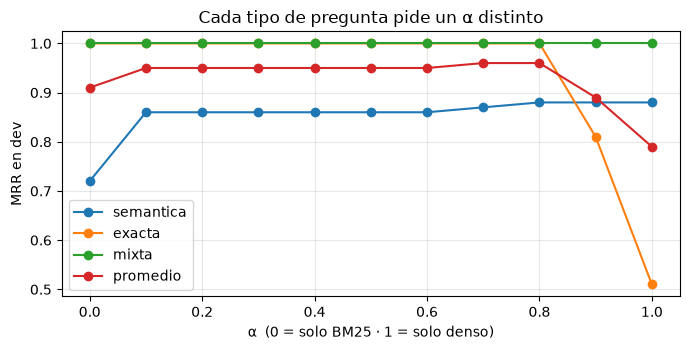

α elegido en dev: 0.7


In [8]:
import matplotlib.pyplot as plt

ax = barrido.plot(figsize=(7, 3.6), marker="o")
ax.set_ylabel("MRR en dev")
ax.set_xlabel("α  (0 = solo BM25 · 1 = solo denso)")
ax.set_title("Cada tipo de pregunta pide un α distinto")
ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

mejor = float(barrido["promedio"].idxmax())
print("α elegido en dev:", mejor)

In [9]:
final = {
    "denso": lambda q: r_denso(q),
    "bm25": lambda q: r_bm25(q),
    "rrf 1:1": lambda q: rrf([r_denso(q), r_bm25(q)]),
    f"convexa α={mejor}": lambda q: convexa(q, mejor),
}
res_test = pd.concat({n: evaluar(fn, test) for n, fn in final.items()}, axis=1)
res_test

denso        bm25       rrf 1:1       convexa α=0.7      
               hit@3   MRR hit@3   MRR   hit@3   MRR         hit@3   MRR
tipo                                                                    
exacta          0.67  0.30  1.00  1.00    1.00  1.00           1.0  0.92
mixta           1.00  0.88  1.00  1.00    1.00  1.00           1.0  1.00
semantica       1.00  1.00  0.17  0.08    0.83  0.61           1.0  0.75
PROMEDIO TIPOS  0.89  0.73  0.72  0.69    0.94  0.87           1.0  0.89

In [10]:
prom = {n: res_test[n].loc["PROMEDIO TIPOS", "MRR"] for n in final}
print("MRR promedio en TEST:", prom)
assert prom[f"convexa α={mejor}"] >= max(prom["denso"], prom["bm25"]), "el híbrido calibrado debería igualar o superar a ambos en test"
assert prom[f"convexa α={mejor}"] >= prom["rrf 1:1"], "la calibración no debería quedar por debajo de la fusión simple"
print("El híbrido calibrado iguala o supera a cada método y a la fusión simple en el set de prueba")
print(f"Ganancia de calibrar vs fusión simple: {prom[f'convexa α={mejor}'] - prom['rrf 1:1']:+.2f} MRR. "
      "Con 16 preguntas de prueba eso equivale a casi una pregunta: no es concluyente.")

MRR promedio en TEST: {'denso': np.float64(0.73), 'bm25': np.float64(0.69), 'rrf 1:1': np.float64(0.87), 'convexa α=0.7': np.float64(0.89)}
El híbrido calibrado iguala o supera a cada método y a la fusión simple en el set de prueba
Ganancia de calibrar vs fusión simple: +0.02 MRR. Con 16 preguntas de prueba eso equivale a casi una pregunta: no es concluyente.


## Qué te llevas

1. **No existe un ganador absoluto**: depende del tipo de pregunta. Por eso hay que *clasificar* tus preguntas antes de elegir.
2. **Fusionar casi siempre ayuda**: aun con pesos iguales, el híbrido superó a cada método solo. Lo que paga es cubrir los dos tipos de pregunta.
3. **Calibrar afina, no es magia**: recuperó parte de lo que la fusión cuesta en las semánticas, pero con 16 preguntas de prueba la mejora sobre la fusión simple no es concluyente. Calibra en un set y reporta en otro; en producción, un *golden set* de 50–100 preguntas reales.
4. **BM25 puede devolver vacío** cuando no hay coincidencias: es una señal útil, no un fallo. Rellenar con documentos de puntaje 0 solo agrega ruido (en una primera versión de este notebook lo hacíamos y la fusión parecía peor de lo que es).
5. Con corpus chico todo parece fácil; el híbrido paga cuando hay **muchos documentos parecidos** (catálogos, logs, contratos).

➡️ Siguiente: `02_vectorless_arbol_de_documento.ipynb` — qué pasa cuando el documento es largo y tiene estructura.

---
*Webinar «RAG para Soluciones Productivas» · Manuel Argüelles · datos 100 % sintéticos de «Andina Retail»: las cifras ilustran un criterio de decisión, no miden tu sistema. Mide siempre con tus propios datos.*